# 03 · Augmentation

Every augmentation is tied to something measured in the data, and its strength is **calibrated** so the
augmented images cover the range of real images (including the degraded ones and the test set) without
going far beyond it.

Working resolution: **1024 px** (notebook 01: keeps nearly all filaments ≥ 3 px wide).
Input: `preprocess(mode="full")` (notebook 02: best filament/background separability).

| Augmentation | Motivated by |
|---|---|
| rotation (any angle) + flips about the disk centre | disk centred and fixed in size (R = 906 ± 1.6 px); filaments occur at every position and orientation |
| contrast scaling | disk contrast differs between sites and images |
| smooth haze field | residual large-scale variation, much stronger in degraded images (bright halo / haze) |
| blur / sharpen | seeing differs between images and sites |

**Not used:** scaling/zoom (disk size never varies), elastic deformation and cutout (can break or erase thin
filaments, hurting structural continuity), additive noise (no evidence of noise differences beyond what
contrast/sharpness capture).

In [1]:
# --- Setup: works both locally and on Kaggle ---
import os, sys
from pathlib import Path

IN_KAGGLE = os.path.exists("/kaggle/input")

if IN_KAGGLE:
    # Pull the shared src/ code from GitHub (requires Internet ON in notebook settings)
    if not Path("/kaggle/working/COS711-A2").exists():
        !git clone -q https://github.com/AryanMohanlall/COS711-A2.git /kaggle/working/COS711-A2
    ROOT = Path("/kaggle/working/COS711-A2")
else:
    ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

sys.path.insert(0, str(ROOT))

from src.data import get_data_dir
DATA_DIR = get_data_dir()
print("Kaggle:", IN_KAGGLE, "| data dir:", DATA_DIR)

Kaggle: False | data dir: C:\Users\aryan\OneDrive\Documents\COS711\A2\COS711-A2\data\MAGFiLO_1.0_Kaggle_2026


In [2]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

from src.data import SITES, load_annotations, list_test_images, load_image, instance_mask_for
from src.preprocess import preprocess, disk_mask
from src.augment import Augmenter, AugConfig, NO_AUG

FIG_DIR = ROOT / "figures" / "03"
ART_DIR = ROOT / "artifacts"
FIG_DIR.mkdir(parents=True, exist_ok=True)

def savefig(name):
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.precision", 4)

S = 1024                     # working resolution
K = S / 2048                 # full-res → working-res scale
images, anns = load_annotations(DATA_DIR)
test = list_test_images(DATA_DIR)
img_stats = pd.read_csv(ART_DIR / "image_stats.csv")
excluded = pd.read_csv(ART_DIR / "excluded_annotations.csv")
anns = anns[~anns.id.isin(excluded.ann_id)].reset_index(drop=True)
geo_full = img_stats.set_index("obs")[["cx", "cy", "radius"]]
degraded = set(img_stats.loc[img_stats.outlier_score > 5, "obs"])
paths = {**dict(zip(images.obs, images.path)), **dict(zip(test.obs, test.path))}

def load_working(obs):
    """Preprocessed image at working resolution + disk geometry at working resolution."""
    g = tuple(geo_full.loc[obs])
    x = cv2.resize(preprocess(load_image(paths[obs]), "full", g), (S, S), interpolation=cv2.INTER_AREA)
    return x, tuple(v * K for v in g)

C:\Users\aryan\OneDrive\Documents\COS711\A2\COS711-A2\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Calibration: how much do real images vary?

Three appearance measures, on the disk (r < 0.9 R) of every train and test image after preprocessing:

- **contrast**: robust std (1.4826 × MAD) of pixel values
- **haze**: std of the image blurred with σ = 32 px, i.e. large-scale variation left after flattening
- **sharpness**: std of the Laplacian divided by contrast (fine detail relative to overall contrast)

In [3]:
def appearance(x, g):
    core = disk_mask(x.shape, *g, 0.9)
    v = x[core]
    contrast = 1.4826 * np.median(np.abs(v - np.median(v)))
    return {"contrast": contrast,
            "haze": cv2.GaussianBlur(x, (0, 0), 32)[core].std(),
            "sharpness": cv2.Laplacian(x, cv2.CV_32F, ksize=3)[core].std() / contrast}

rows = []
for _, r in tqdm(img_stats.iterrows(), total=len(img_stats)):
    x, g = load_working(r.obs)
    rows.append({"obs": r.obs, "split": r.split, "site": r.site, "degraded": r.obs in degraded, **appearance(x, g)})
real = pd.DataFrame(rows)
real.to_csv(ART_DIR / "appearance_1024.csv", index=False)

med = real[["contrast", "haze", "sharpness"]].median()
q = real.groupby("degraded")[["contrast", "haze", "sharpness"]].quantile([0.05, 0.5, 0.95]).unstack()
q

  0%|          | 0/887 [00:00<?, ?it/s]

  0%|          | 1/887 [00:00<07:28,  1.97it/s]

  0%|          | 2/887 [00:00<06:01,  2.44it/s]

  0%|          | 3/887 [00:01<06:05,  2.42it/s]

  0%|          | 4/887 [00:01<06:26,  2.28it/s]

...

100%|█████████▉| 885/887 [10:51<00:00,  2.08it/s]

100%|█████████▉| 886/887 [10:52<00:00,  2.38it/s]

100%|██████████| 887/887 [10:52<00:00,  2.12it/s]

100%|██████████| 887/887 [10:52<00:00,  1.36it/s]

contrast                    haze                 sharpness          \
             0.05    0.50    0.95    0.05    0.50    0.95      0.05    0.50   
degraded                                                                      
False      0.0314  0.0476  0.0641  0.0064  0.0114  0.0179    4.2772  5.1346   
True       0.0270  0.0460  0.0645  0.0071  0.0138  0.0293    4.1451  5.1425   

                  
            0.95  
degraded          
False     6.2693  
True      6.7007

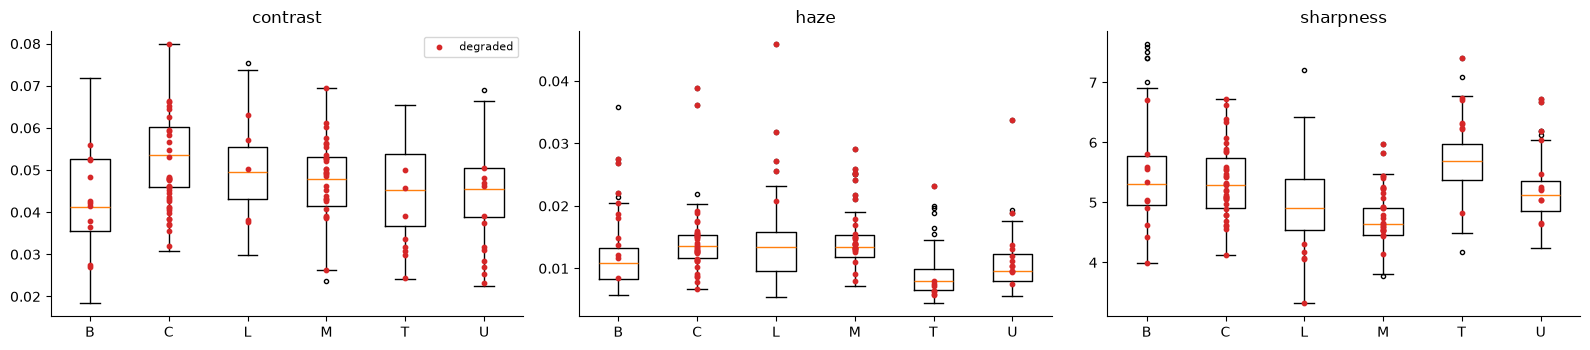

Relative to the median image:
      contrast  sharpness
0.00     0.387      0.646
0.05     0.653      0.829
0.95     1.354      1.233
1.00     1.684      1.487


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.6))
for ax, col in zip(axes, ["contrast", "haze", "sharpness"]):
    data = [real.loc[real.site == s, col] for s in SITES]
    ax.boxplot(data, tick_labels=list(SITES), flierprops={"markersize": 3})
    deg = real[real.degraded]
    ax.scatter([list(SITES).index(s) + 1 for s in deg.site], deg[col], s=10, c="tab:red", zorder=3, label="degraded")
    ax.set_title(col)
axes[0].legend(fontsize=8); plt.tight_layout(); savefig("appearance_by_site"); plt.show()

rel = (real[["contrast", "sharpness"]] / med[["contrast", "sharpness"]]).quantile([0.0, 0.05, 0.95, 1.0])
print("Relative to the median image:"); print(rel.round(3))

**Reading this:**
- *contrast*: 5th–95th percentile ≈ ×0.65 to ×1.35 of the median → contrast factor drawn from **[0.65, 1.35]**
- *haze*: typical ≈ 0.011; degraded images reach ≈ 0.029 (95th pct) → with probability 0.3, add a smooth field
  with std drawn from **[0.005, 0.028]**
- *sharpness*: spans ≈ 0.82–1.30 × median (min ≈ 0.65) → map out which blur/sharpen strength produces that

In [5]:
calib_obs = images.drop_duplicates("obs").sample(12, random_state=1).obs
curve = []
for obs in calib_obs:
    x, g = load_working(obs)
    base = appearance(x, g)["sharpness"]
    for s in [0.3, 0.4, 0.5, 0.65, 0.8, 1.0]:
        curve.append({"op": "blur σ", "strength": s, "ratio": appearance(cv2.GaussianBlur(x, (0, 0), s), g)["sharpness"] / base})
    for a in [0.2, 0.3, 0.5, 0.8, 1.0]:
        y = x + a * (x - cv2.GaussianBlur(x, (0, 0), 1.0))
        curve.append({"op": "sharpen amount", "strength": a, "ratio": appearance(y, g)["sharpness"] / base})
curve = pd.DataFrame(curve).groupby(["op", "strength"]).ratio.mean().unstack(0)
curve

op,blur σ,sharpen amount
strength,,
0.20,NaN,1.0795
0.30,0.9930,1.1146
0.40,0.9242,NaN
0.50,0.7921,1.1767
0.65,0.6217,NaN
0.80,0.5147,1.2526
1.00,0.4172,1.2942


Blur σ ≈ 0.4–0.65 px lowers sharpness to ≈ 0.85–0.6 × (the blurriest real images), and unsharp masking with
amount 0.3–0.8 raises it to ≈ 1.1–1.25 × (the sharpest). These are the ranges in `AugConfig`.

In [6]:
AugConfig()

AugConfig(rotate=True, flip=True, contrast=(0.65, 1.35), haze_prob=0.3, haze_std=(0.005, 0.028), haze_grid=4, blur_prob=0.25, blur_sigma=(0.4, 0.65), sharpen_prob=0.15, sharpen_amount=(0.3, 0.8), limb_cut=0.985)

Rotation itself resamples the image. Measured on 10 images (sharpness after / before rotating by 37°):
bilinear ×0.80, bicubic ×0.95, Lanczos ×1.00. A first version of the augmenter used bilinear and the
coverage check below showed every augmented image blurrier than real ones, so rotation uses **Lanczos**.

In [7]:
rot_check = []
for obs in calib_obs[:10]:
    x, g = load_working(obs)
    base = appearance(x, g)["sharpness"]
    M = cv2.getRotationMatrix2D(g[:2], 37, 1.0)
    for name, flag in [("bilinear", cv2.INTER_LINEAR), ("bicubic", cv2.INTER_CUBIC), ("lanczos", cv2.INTER_LANCZOS4)]:
        y = cv2.warpAffine(x, M, (S, S), flags=flag, borderValue=1.0)
        rot_check.append({"interpolation": name, "sharpness ratio": appearance(y, g)["sharpness"] / base})
pd.DataFrame(rot_check).groupby("interpolation").mean()

,sharpness ratio
interpolation,
bicubic,0.9581
bilinear,0.8075
lanczos,1.0133


## 2. What the augmentations look like

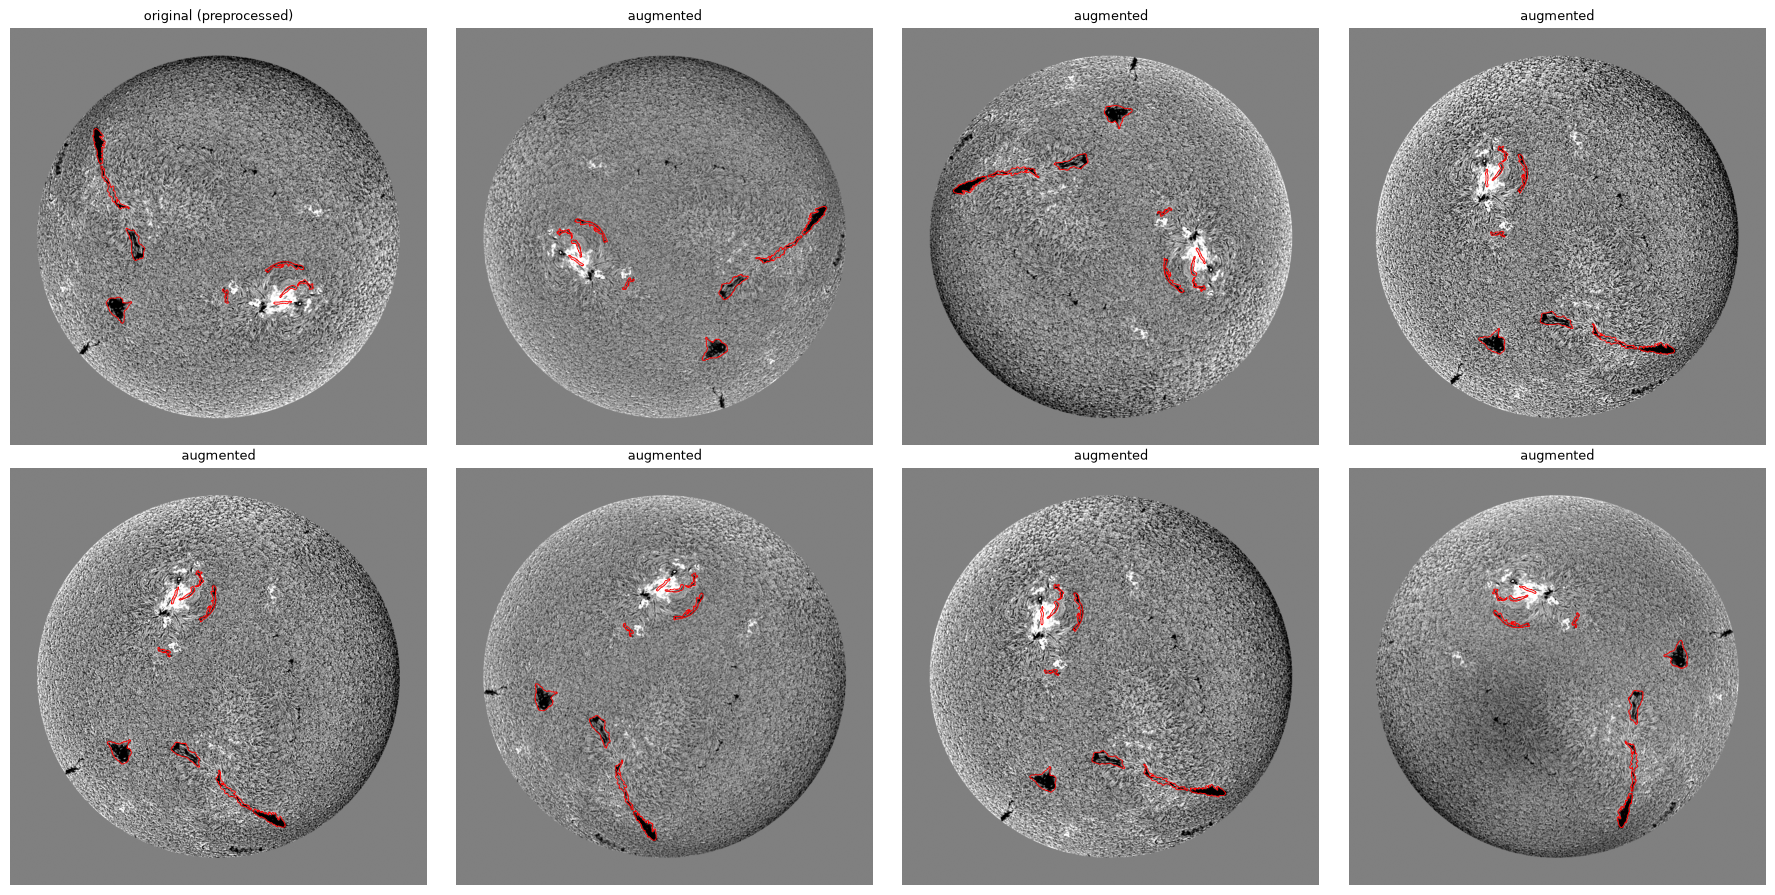

In [8]:
obs = "20150825082034Lh"
x, g = load_working(obs)
iid = images.loc[images.obs == obs, "image_id"].iloc[0]
m = instance_mask_for(iid, anns, (S, S), K)

def show(ax, img, mask, title, crop=None):
    crop = crop or (slice(None), slice(None))
    ax.imshow(img[crop], cmap="gray", vmin=0.8, vmax=1.2)
    if mask is not None:
        ax.contour((mask[crop] > 0).astype(float), levels=[0.5], colors="r", linewidths=0.6)
    ax.set_title(title, fontsize=9); ax.set_axis_off()

aug = Augmenter(AugConfig(), seed=3)
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
show(axes.flat[0], x, m, "original (preprocessed)")
for ax in axes.flat[1:]:
    y, (ma,) = aug(x, [m], g)
    show(ax, y, ma, "augmented")
plt.tight_layout(); savefig("augmented_samples"); plt.show()

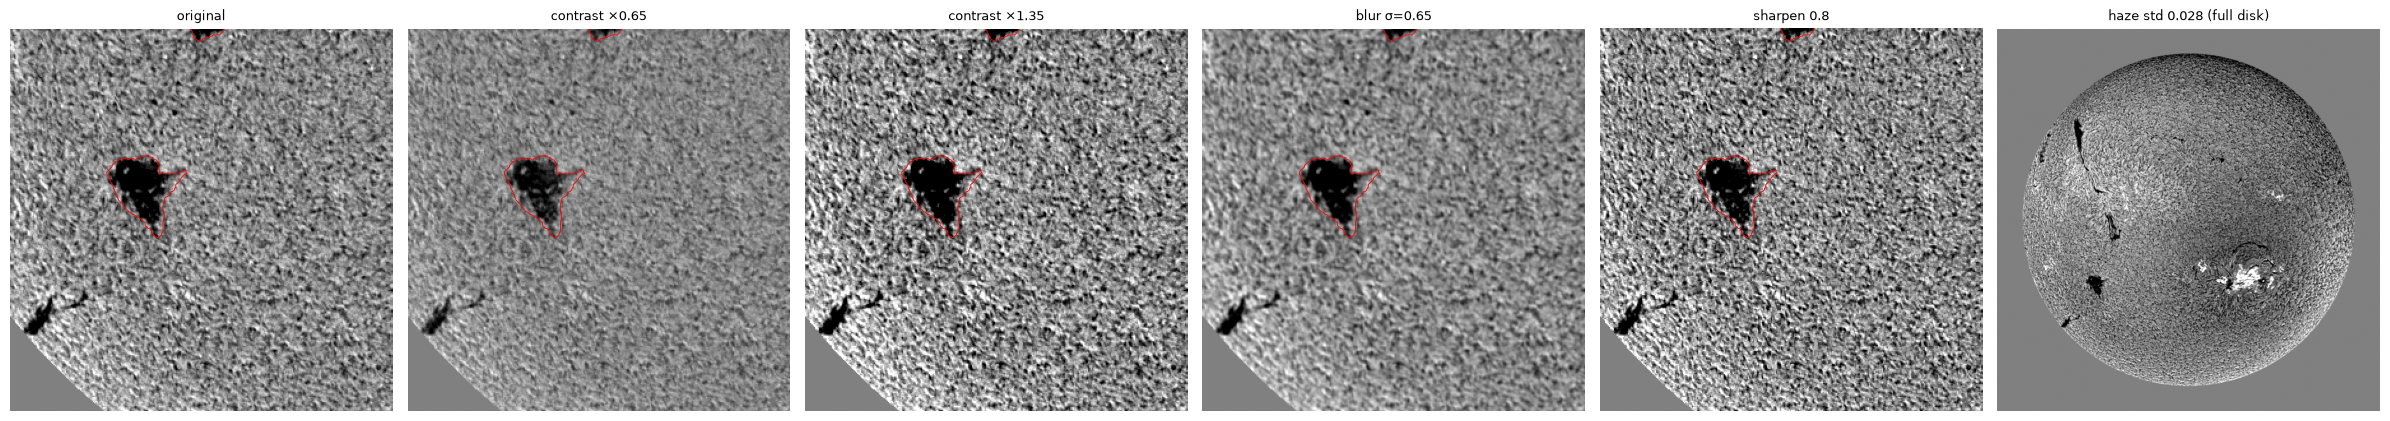

In [9]:
# Each photometric effect on its own, zoomed in, at the extremes of its range
crop = (slice(560, 860), slice(160, 460))
single = {
    "original": NO_AUG,
    "contrast ×0.65": AugConfig(rotate=False, flip=False, contrast=(0.65, 0.65), haze_prob=0, blur_prob=0, sharpen_prob=0),
    "contrast ×1.35": AugConfig(rotate=False, flip=False, contrast=(1.35, 1.35), haze_prob=0, blur_prob=0, sharpen_prob=0),
    "blur σ=0.65": AugConfig(rotate=False, flip=False, contrast=(1, 1), haze_prob=0, blur_prob=1, blur_sigma=(0.65, 0.65), sharpen_prob=0),
    "sharpen 0.8": AugConfig(rotate=False, flip=False, contrast=(1, 1), haze_prob=0, blur_prob=0, sharpen_prob=1, sharpen_amount=(0.8, 0.8)),
}
fig, axes = plt.subplots(1, len(single) + 1, figsize=(4 * (len(single) + 1), 4.3))
for ax, (name, cfg) in zip(axes, single.items()):
    y, (ma,) = Augmenter(cfg, seed=0)(x, [m], g)
    show(ax, y, ma, name, crop)
y, _ = Augmenter(AugConfig(rotate=False, flip=False, contrast=(1, 1), haze_prob=1, haze_std=(0.028, 0.028),
                           blur_prob=0, sharpen_prob=0), seed=0)(x, [], g)
axes[-1].imshow(y, cmap="gray", vmin=0.8, vmax=1.2); axes[-1].set_title("haze std 0.028 (full disk)", fontsize=9)
axes[-1].set_axis_off()
plt.tight_layout(); savefig("single_effects"); plt.show()

## 3. Coverage check: do augmented images span the real range?

Augment each *non-degraded* training image several times and compare the appearance measures of the
augmented images with those of the real images, in particular the degraded ones and the test set,
which the augmentations are meant to prepare the model for.

  0%|          | 0/150 [00:00<?, ?it/s]

  1%|          | 1/150 [00:02<05:36,  2.26s/it]

  1%|▏         | 2/150 [00:02<02:44,  1.11s/it]

  2%|▏         | 3/150 [00:02<01:49,  1.34it/s]

  3%|▎         | 4/150 [00:03<01:46,  1.37it/s]

...

 98%|█████████▊| 147/150 [01:20<00:01,  1.97it/s]

 99%|█████████▊| 148/150 [01:22<00:01,  1.10it/s]

 99%|█████████▉| 149/150 [01:23<00:00,  1.37it/s]

100%|██████████| 150/150 [01:25<00:00,  1.16s/it]

100%|██████████| 150/150 [01:25<00:00,  1.76it/s]

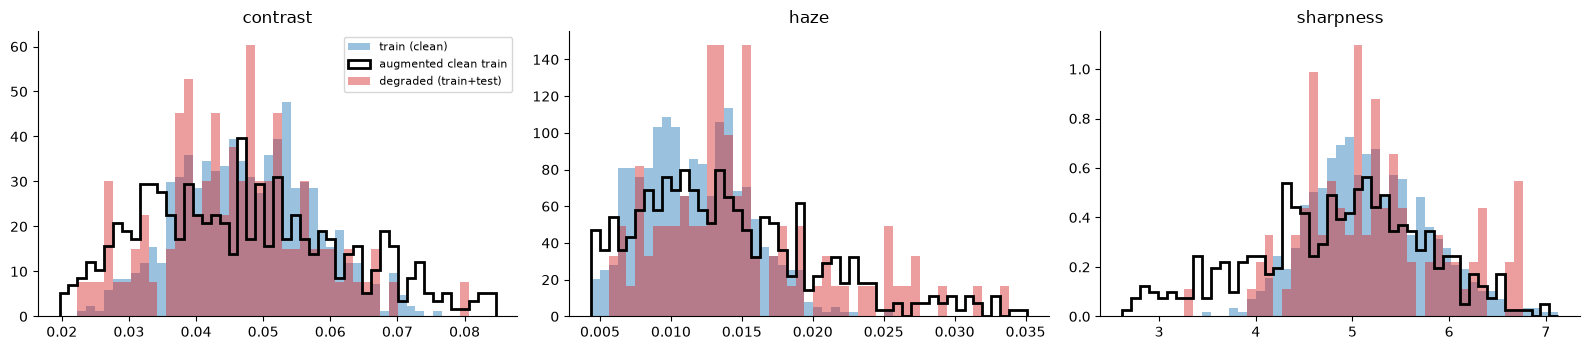

Share of real images inside the augmented 1–99% range on all three measures:
  clean train before augmentation: 97.8%
  degraded (train + test):         89.0%
  test:                            95.6%


In [10]:
aug = Augmenter(AugConfig(), seed=0)
clean_train = real[(real.split == "train") & ~real.degraded].sample(150, random_state=0).obs
rows = []
for obs in tqdm(clean_train):
    x, g = load_working(obs)
    for _ in range(3):
        y, _ = aug(x, [], g)
        rows.append(appearance(y, g))
augd = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 3, figsize=(16, 3.6))
for ax, col in zip(axes, ["contrast", "haze", "sharpness"]):
    lo, hi = np.percentile(np.r_[real[col], augd[col]], [0.5, 99.5])
    bins = np.linspace(lo, hi, 50)
    ax.hist(real.loc[~real.degraded & (real.split == "train"), col], bins, density=True, alpha=0.45, label="train (clean)")
    ax.hist(augd[col], bins, density=True, histtype="step", lw=2, color="k", label="augmented clean train")
    ax.hist(real.loc[real.degraded, col], bins, density=True, alpha=0.45, color="tab:red", label="degraded (train+test)")
    ax.set_title(col)
axes[0].legend(fontsize=8); plt.tight_layout(); savefig("coverage"); plt.show()

lo, hi = augd.quantile(0.01), augd.quantile(0.99)
inside = lambda df: ((df[augd.columns] >= lo) & (df[augd.columns] <= hi)).all(axis=1).mean()
print(f"Share of real images inside the augmented 1–99% range on all three measures:")
print(f"  clean train before augmentation: {inside(real[(real.split == 'train') & ~real.degraded]):.1%}")
print(f"  degraded (train + test):         {inside(real[real.degraded]):.1%}")
print(f"  test:                            {inside(real[real.split == 'test']):.1%}")

## 4. Label integrity: do resizing and rotation break thin filaments?

Fragmenting a filament into pieces is exactly what PQ punishes, so the training labels must not do it.
For 300 annotation sets, compare at 1024 px:

- **resize**: rasterising the 2048 px mask then nearest-neighbour resizing vs **rasterising the polygons
  directly at 1024 px** (`instance_mask(..., scale=0.5)`)
- **rotation**: the direct mask before vs after a random rotation (nearest-neighbour)

and count instances that disappear or split into more than one connected piece.

In [11]:
def frag_stats(mask):
    ids = np.unique(mask)[1:]
    pieces = [cv2.connectedComponents((mask == k).astype(np.uint8), connectivity=8)[0] - 1 for k in ids]
    return len(ids), sum(p > 1 for p in pieces), int((mask > 0).sum())

rot = Augmenter(AugConfig(contrast=(1, 1), haze_prob=0, blur_prob=0, sharpen_prob=0), seed=0)
rows = []
for iid in tqdm(images.sample(300, random_state=0).image_id):
    n_true = int((anns.image_id == iid).sum())
    direct = instance_mask_for(iid, anns, (S, S), K)
    resized = cv2.resize(instance_mask_for(iid, anns).astype(np.float32), (S, S),
                         interpolation=cv2.INTER_NEAREST).astype(np.int32)
    _, (rotated,) = rot(np.ones((S, S), np.float32), [direct])
    for name, mm in [("nearest-resized", resized), ("direct 1024", direct), ("direct 1024 + rotation", rotated)]:
        n, split, area = frag_stats(mm)
        rows.append({"method": name, "instances": n_true, "lost": n_true - n, "fragmented": split, "pixels": area})
li = pd.DataFrame(rows).groupby("method").sum()
li["fragmented %"] = 100 * li.fragmented / li.instances
li["pixels vs direct"] = li.pixels / li.loc["direct 1024", "pixels"]
li

  0%|          | 0/300 [00:00<?, ?it/s]

  0%|          | 1/300 [00:00<03:17,  1.52it/s]

  1%|          | 3/300 [00:00<01:11,  4.17it/s]

  2%|▏         | 5/300 [00:01<00:46,  6.31it/s]

  2%|▏         | 6/300 [00:01<00:44,  6.63it/s]

...

 99%|█████████▉| 297/300 [00:31<00:00,  8.72it/s]

 99%|█████████▉| 298/300 [00:31<00:00,  8.52it/s]

100%|██████████| 300/300 [00:32<00:00,  8.10it/s]

100%|██████████| 300/300 [00:32<00:00,  9.30it/s]

,instances,lost,fragmented,pixels,fragmented %,pixels vs direct
method,,,,,,
direct 1024,2149,0,0,1357497,0.0000,1.0000
direct 1024 + rotation,2149,0,5,1357260,0.2327,0.9998
nearest-resized,2149,0,1,1260646,0.0465,0.9287


## Summary

| Augmentation | Calibrated from | Setting (`src.augment.AugConfig`) |
|---|---|---|
| Rotation, any angle, about the disk centre + horizontal/vertical flips | Disk centred, R = 906 ± 1.6 px | always; **Lanczos** interpolation (bilinear blurred images to ×0.81 sharpness) |
| Contrast scaling around 1 | Disk contrast 5th–95th pct = ×0.65–×1.35 of median | factor ∈ [0.65, 1.35] |
| Smooth haze field (4×4 cubic-interpolated noise) | Residual haze 0.011 typical, 0.029 at 95th pct of degraded | p = 0.3, std ∈ [0.005, 0.028] |
| Blur | Sharpness down to ×0.65–0.83 of median | p = 0.25, σ ∈ [0.4, 0.65] px |
| Sharpen (unsharp mask) | Sharpness up to ×1.23–1.49 of median | p = 0.15, amount ∈ [0.3, 0.8] |

**Coverage:** after augmenting clean training images, **95.6% of test images** and **89% of degraded images**
fall inside the augmented 1–99% range on all three appearance measures. Unaugmented clean training images
alone cover only part of that range (see `figures/03/coverage.png`). The remaining degraded outliers are
the most extreme haze cases (> 0.03).

**Label integrity at 1024 px:** rasterising polygons directly at 1024 px keeps 7% more filament pixels than
resizing the 2048 px mask (thin parts survive). Random rotation loses no filaments and fragments 0.23% of
instances (5 of 2149, single-pixel bridges). Negligible, so labels are rotated as masks.

**Not used:** zoom/scale (disk size constant), elastic deformation and cutout (risk breaking or erasing thin
filaments, which PQ punishes), additive noise (no measured need).

**For notebook 04:** compare training with `AugConfig()` vs geometric-only vs `NO_AUG` to show how much
each part helps.
